# Exploratory Data Analysis (EDA): revisión y calidad de datos

**Proyecto:** GoEmotions — clasificación de comentarios por sentimiento  
**Commit:** IT2-11  
**Responsable:** Daniel Varela

## Objetivo

Explorar los archivos originales de GoEmotions antes de utilizar los datos en los modelos. Se revisarán la estructura, los tipos de datos, los valores faltantes, los registros duplicados, la distribución de emociones y grupos de sentimiento, y la presencia de tokens enmascarados.

Este notebook documenta la inspección de los datos originales. No modifica los archivos de entrada ni realiza transformaciones para entrenamiento.

## 1. Preparación y carga de los datos

Se utiliza la implementación compartida del proyecto en `src/preprocessing.py` para cargar los tres archivos TSV y aplicar el mapeo oficial de emociones a grupos de sentimiento. Los archivos se concatenan para realizar la revisión sobre el conjunto completo.

In [1]:
from pathlib import Path
import re
import sys

import pandas as pd
from IPython.display import display

# Encontrar la raíz del repositorio aunque Jupyter se inicie desde notebooks/.
CANDIDATES = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in CANDIDATES if (p / "src" / "preprocessing.py").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró src/preprocessing.py. Abra Jupyter desde la raíz del proyecto."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    load_goemotions,
    load_sentiment_mapping,
    load_emotion_names,
    assign_sentiment,
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"

In [2]:
# Carga de los archivos originales y construcción de la tabla con etiquetas.
df_raw = load_goemotions(RAW_DIR)
sentiment_mapping = load_sentiment_mapping(RAW_DIR)
emotion_names = load_emotion_names(RAW_DIR)
df = assign_sentiment(df_raw, sentiment_mapping)

print(f"Registros cargados: {len(df):,}")
print(f"Columnas: {df.columns.tolist()}")
print(f"Emociones definidas: {len(emotion_names)}")
display(df.head())

Registros cargados: 54,263
Columnas: ['comment_id', 'text', 'emotion_ids', 'emotions', 'sentiment']
Emociones definidas: 28


,comment_id,text,emotion_ids,emotions,sentiment
0,eebbqej,My favourite food is anything I didn't have to...,[27],[neutral],neutral
1,ed00q6i,"Now if he does off himself, everyone will thin...",[27],[neutral],neutral
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,[2],[anger],negative
3,ed7ypvh,To make her feel threatened,[14],[fear],negative
4,ed0bdzj,Dirty Southern Wankers,[3],[annoyance],negative


**Qué observamos:** la función de carga reúne `train.tsv`, `dev.tsv` y `test.tsv`. Cada fila representa un comentario e incluye su identificador, texto, identificadores de emoción, nombres de emoción y grupo de sentimiento asignado. En las siguientes secciones se verificará que la estructura y las cantidades correspondan con lo esperado.

## 2. Exploración inicial de la estructura

Se aplican las inspecciones básicas solicitadas: `head()`, `shape`, `info()` y `describe()`. Estas permiten conocer el tamaño del conjunto, los nombres y tipos de columnas y un resumen de los campos disponibles.

In [3]:
print("Primeras cinco filas:")
display(df.head())

print("\nDimensiones (filas, columnas):")
print(df.shape)

print("\nInformación general:")
df.info()

print("\nResumen descriptivo de las columnas:")
display(df.describe(include="all").T)

Primeras cinco filas:


,comment_id,text,emotion_ids,emotions,sentiment
0,eebbqej,My favourite food is anything I didn't have to...,[27],[neutral],neutral
1,ed00q6i,"Now if he does off himself, everyone will thin...",[27],[neutral],neutral
2,eezlygj,WHY THE FUCK IS BAYLESS ISOING,[2],[anger],negative
3,ed7ypvh,To make her feel threatened,[14],[fear],negative
4,ed0bdzj,Dirty Southern Wankers,[3],[annoyance],negative



Dimensiones (filas, columnas):
(54263, 5)

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54263 entries, 0 to 54262
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   comment_id   54263 non-null  object
 1   text         54263 non-null  object
 2   emotion_ids  54263 non-null  object
 3   emotions     54263 non-null  object
 4   sentiment    54263 non-null  object
dtypes: object(5)
memory usage: 2.1+ MB

Resumen descriptivo de las columnas:


,count,unique,top,freq
comment_id,54263,54263,eebbqej,1
text,54263,53994,Thank you.,15
emotion_ids,54263,782,[27],16021
emotions,54263,782,[neutral],16021
sentiment,54263,5,positive,19020


**Qué observamos:** `shape` informa el tamaño total de la tabla; `info()` permite revisar los tipos de datos y la cantidad de valores no nulos; `describe()` resume las columnas. Las columnas `emotion_ids` y `emotions` contienen listas, por lo que sus estadísticas descriptivas no equivalen a un conteo individual de cada emoción.

## 3. Calidad de los datos: valores faltantes

Se cuentan los valores faltantes por columna. La comprobación se realiza sobre la tabla cargada y etiquetada, sin reemplazar ni eliminar registros.

In [4]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "missing_values": missing_by_column,
    "missing_percent": (missing_by_column / len(df) * 100).round(4),
})
display(missing_summary)
print("Total de valores faltantes:", int(df.isna().sum().sum()))

,missing_values,missing_percent
comment_id,0,0.0
text,0,0.0
emotion_ids,0,0.0
emotions,0,0.0
sentiment,0,0.0


Total de valores faltantes: 0


**Qué observamos:** la tabla permite identificar si alguna columna presenta valores faltantes y qué proporción representan. Si el total es cero, significa que no se detectaron valores `NaN` en las columnas cargadas; esto no reemplaza la revisión de cadenas vacías, que se realiza a continuación.

In [5]:
empty_text = df["text"].astype(str).str.strip().eq("")
empty_comment_id = df["comment_id"].astype(str).str.strip().eq("")
empty_emotion_ids = df["emotion_ids"].map(len).eq(0)

empty_summary = pd.Series({
    "text_empty_or_whitespace": int(empty_text.sum()),
    "comment_id_empty": int(empty_comment_id.sum()),
    "emotion_ids_empty": int(empty_emotion_ids.sum()),
}, name="count")
display(empty_summary.to_frame())

,count
text_empty_or_whitespace,0
comment_id_empty,0
emotion_ids_empty,0


**Qué observamos:** los valores vacíos como cadenas no siempre son considerados valores nulos por Pandas. Por eso se revisan por separado el texto, el identificador del comentario y la lista de emociones.

## 4. Registros duplicados

Se revisan los identificadores repetidos y los textos repetidos. El texto se normaliza únicamente para esta comparación (minúsculas, eliminación de espacios al inicio/final y compactación de espacios consecutivos). No se eliminan duplicados en este notebook.

In [6]:
duplicate_ids = int(df["comment_id"].duplicated().sum())
normalized_text = df["text"].astype(str).str.lower().str.split().str.join(" ")
duplicate_text_rows = int(normalized_text.duplicated().sum())

duplicate_summary = pd.DataFrame({
    "check": ["Repeated comment_id", "Repeated normalized text"],
    "duplicate_rows": [duplicate_ids, duplicate_text_rows],
})
display(duplicate_summary)

,check,duplicate_rows
0,Repeated comment_id,0
1,Repeated normalized text,320


**Qué observamos:** los resultados indican cuántas filas repiten un identificador o un texto normalizado. Esta revisión es descriptiva: no modifica el conjunto original. La construcción del dataset balanceado tiene su propia política de tratamiento de duplicados en `src/preprocessing.py`.

## 5. Distribución de emociones

Cada comentario puede tener una o más emociones. Para obtener la frecuencia de cada emoción individual, se expanden las listas de la columna `emotions` y se cuentan sus apariciones.

In [7]:
emotion_counts = (
    df["emotions"]
    .explode()
    .value_counts()
    .rename_axis("emotion")
    .reset_index(name="occurrences")
)
display(emotion_counts)
print("Total de asignaciones de emociones:", int(emotion_counts["occurrences"].sum()))

,emotion,occurrences
0,neutral,17772
1,admiration,5122
2,approval,3687
3,gratitude,3372
4,annoyance,3093
5,amusement,2895
6,curiosity,2723
7,disapproval,2581
8,love,2576
9,optimism,1976


Total de asignaciones de emociones: 63812


**Qué observamos:** las frecuencias representan asignaciones de emociones, no necesariamente comentarios únicos, porque un comentario puede tener varias etiquetas. Por esta razón, la suma de apariciones puede ser mayor que el número de comentarios.

## 6. Distribución de grupos de sentimiento y comparación con el enunciado

El mapeo del proyecto agrupa las emociones en `positive`, `negative`, `ambiguous` y `neutral`; los comentarios cuyas emociones pertenecen a más de un grupo se clasifican como `mixed`. Se comparan los conteos obtenidos sobre el conjunto completo con las cifras de referencia del enunciado.

In [8]:
expected_counts = pd.Series({
    "positive": 19020,
    "negative": 10217,
    "ambiguous": 4805,
    "neutral": 16021,
    "mixed": 4200,
}, name="expected")

observed_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(expected_counts.index, fill_value=0)
    .rename("observed")
)

comparison = pd.concat([expected_counts, observed_counts], axis=1)
comparison["difference"] = comparison["observed"] - comparison["expected"]
comparison["matches"] = comparison["difference"].eq(0)
display(comparison)
print("Total esperado:", int(expected_counts.sum()))
print("Total observado:", int(observed_counts.sum()))
print("¿Coinciden todos los conteos?:", bool(comparison["matches"].all()))

,expected,observed,difference,matches
positive,19020,19020,0,True
negative,10217,10217,0,True
ambiguous,4805,4805,0,True
neutral,16021,16021,0,True
mixed,4200,4200,0,True


Total esperado: 54263
Total observado: 54263
¿Coinciden todos los conteos?: True


**Qué observamos:** la columna `difference` muestra la diferencia entre el conteo calculado y la referencia del enunciado. Un valor cero en `matches` indica que esa categoría coincide exactamente. Si alguna categoría no coincide, se debe documentar la diferencia y revisar el mapeo o la interpretación de las etiquetas antes de continuar.

## 7. Revisión de tokens enmascarados

GoEmotions contiene marcadores que sustituyen nombres o referencias sensibles. Se inspeccionan los marcadores `[NAME]` y `[RELIGION]` en los textos originales. La búsqueda no modifica ni elimina estos tokens.

In [9]:
masked_patterns = {
    "[NAME]": re.compile(r"\[NAME\]", flags=re.IGNORECASE),
    "[RELIGION]": re.compile(r"\[RELIGION\]", flags=re.IGNORECASE),
}

masked_rows = []
for token, pattern in masked_patterns.items():
    counts_per_comment = df["text"].astype(str).map(lambda value: len(pattern.findall(value)))
    masked_rows.append({
        "token": token,
        "comments_containing_token": int(counts_per_comment.gt(0).sum()),
        "total_occurrences": int(counts_per_comment.sum()),
    })

masked_summary = pd.DataFrame(masked_rows)
display(masked_summary)

,token,comments_containing_token,total_occurrences
0,[NAME],7558,9598
1,[RELIGION],121,132


**Qué observamos:** `comments_containing_token` cuenta comentarios que contienen al menos una aparición del marcador; `total_occurrences` cuenta todas las apariciones. Los tokens se mantienen en los datos originales y su tratamiento posterior corresponde a la etapa de limpieza definida en el proyecto.

In [10]:
# Ejemplos para inspección cualitativa, sin modificar los datos.
for token, pattern in masked_patterns.items():
    examples = df.loc[
        df["text"].astype(str).map(lambda value: bool(pattern.search(value))),
        ["comment_id", "text", "sentiment"],
    ].head(5)
    print(f"Ejemplos de {token}:")
    display(examples)

Ejemplos de [NAME]:


,comment_id,text,sentiment
7,ef4qmod,We need more boards and to create a bit more s...,positive
11,edex4ki,"Aww... she'll probably come around eventually,...",positive
14,efdqav7,"[NAME] - same fucking problem, slightly better...",negative
20,efdlhs1,"I never thought it was at the same moment, but...",mixed
26,edafy84,Mine was apparently [NAME] and the giant peach!,neutral


Ejemplos de [RELIGION]:


,comment_id,text,sentiment
76,eellryt,"Awesome! I’m a cradle [RELIGION], so really in...",positive
188,ee5ir1u,You just needed a [RELIGION] grandparent to be...,neutral
904,edke45v,>And I could be wrong about my [RELIGION] fait...,ambiguous
1151,edls9bt,It's normal school except they sexually identi...,positive
1320,eeung0v,His preamble in his book is written by a [RELI...,neutral


## 8. Conclusiones de la revisión de datos

La revisión exploratoria permitió comprobar la estructura, la calidad y la distribución de los archivos originales de GoEmotions antes del modelado.

- **Estructura:** se cargaron **54.263 comentarios** a partir de `train.tsv`, `dev.tsv` y `test.tsv`. La tabla final contiene cinco columnas: `comment_id`, `text`, `emotion_ids`, `emotions` y `sentiment`. Se identificaron **28 emociones** definidas en el conjunto.
- **Valores faltantes y vacíos:** no se detectaron valores nulos (`NaN`) en ninguna columna. Tampoco se encontraron textos vacíos o compuestos solo por espacios, identificadores vacíos ni listas de emociones vacías.
- **Duplicados:** no se encontraron identificadores `comment_id` repetidos. La comparación de textos normalizados detectó **320 filas repetidas**. Este conteo es descriptivo; no se eliminaron registros en este notebook.
- **Distribución de sentimientos:** los conteos observados coinciden exactamente con los valores de referencia: `positive` (19.020), `negative` (10.217), `ambiguous` (4.805), `neutral` (16.021) y `mixed` (4.200). El total es de **54.263 comentarios**.
- **Distribución de emociones:** se identificaron apariciones de las 28 emociones. La emoción `neutral` presenta la mayor frecuencia, con **17.772 apariciones**. Estas frecuencias cuentan asignaciones de emociones; no deben confundirse con el número de comentarios por grupo de sentimiento.
- **Tokens enmascarados:** `[NAME]` aparece en **7.558 comentarios**, con **9.598 apariciones**; `[RELIGION]` aparece en **121 comentarios**, con **132 apariciones**. La inspección y los ejemplos son descriptivos: los marcadores se conservan en los archivos originales.

En conjunto, los resultados confirman que los datos cargados tienen la estructura esperada y que el mapeo de los cinco grupos de sentimiento reproduce exactamente los conteos de referencia. También se identificaron textos repetidos y marcadores enmascarados que deberán considerarse en las etapas de preprocesamiento correspondientes. Este notebook no elimina duplicados, no modifica los archivos originales y no realiza transformaciones para entrenamiento.

## 9. Visualizaciones del análisis exploratorio (IT2-12)

En esta sección se representan gráficamente las distribuciones identificadas en la revisión anterior. Las gráficas se construyen a partir del DataFrame `df` y de los conteos calculados en las secciones previas. No se modifican los datos originales.

### 9.1 Distribución de los grupos de sentimiento

El gráfico de barras permite comparar la cantidad de comentarios en cada grupo de sentimiento. Se muestran los valores absolutos y el porcentaje que representa cada grupo sobre el total.

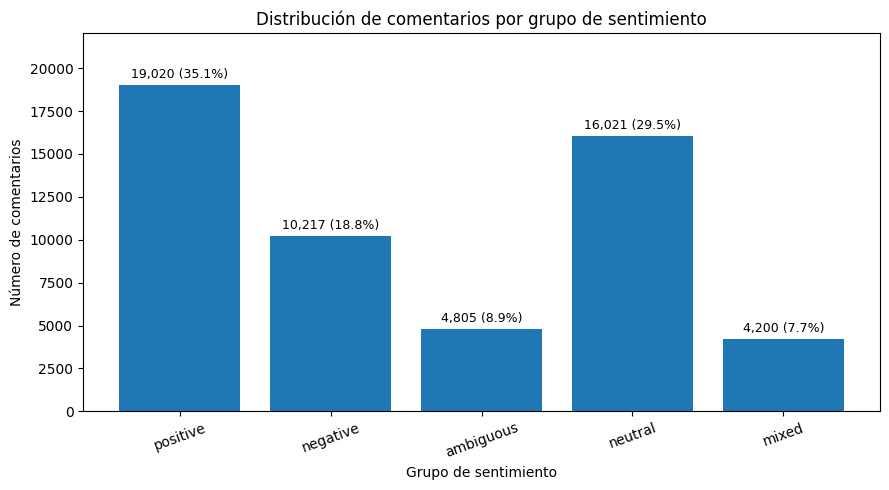

,comments,percentage
sentiment,,
positive,19020,35.05
negative,10217,18.83
ambiguous,4805,8.86
neutral,16021,29.52
mixed,4200,7.74


In [16]:
import matplotlib.pyplot as plt

# Conteos ordenados de acuerdo con las categorías del proyecto.
sentiment_order = ["positive", "negative", "ambiguous", "neutral", "mixed"]
sentiment_plot = (
    df["sentiment"].value_counts().reindex(sentiment_order, fill_value=0)
)
sentiment_percent = sentiment_plot / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(sentiment_plot.index, sentiment_plot.values)
ax.set_title("Distribución de comentarios por grupo de sentimiento")
ax.set_xlabel("Grupo de sentimiento")
ax.set_ylabel("Número de comentarios")
ax.tick_params(axis="x", rotation=20)
ax.bar_label(
    bars,
    labels=[f"{value:,} ({percent:.1f}%)" for value, percent in zip(sentiment_plot.values, sentiment_percent)],
    padding=3,
    fontsize=9,
)
ax.set_ylim(0, max(sentiment_plot.values) * 1.16)
fig.tight_layout()

display(fig)
plt.close(fig)

display(pd.DataFrame({
    "comments": sentiment_plot,
    "percentage": sentiment_percent.round(2)
}))

**Qué observamos:** la altura de las barras permite identificar qué grupos reúnen más comentarios. Las etiquetas muestran tanto el conteo como el porcentaje. Esta visualización facilita comparar el balance entre categorías; no implica que los grupos deban tener exactamente el mismo tamaño.

### 9.2 Emociones individuales más frecuentes

Como un comentario puede tener más de una emoción, se muestran las 15 emociones con mayor número de asignaciones. Se utiliza un gráfico horizontal para facilitar la lectura de los nombres.

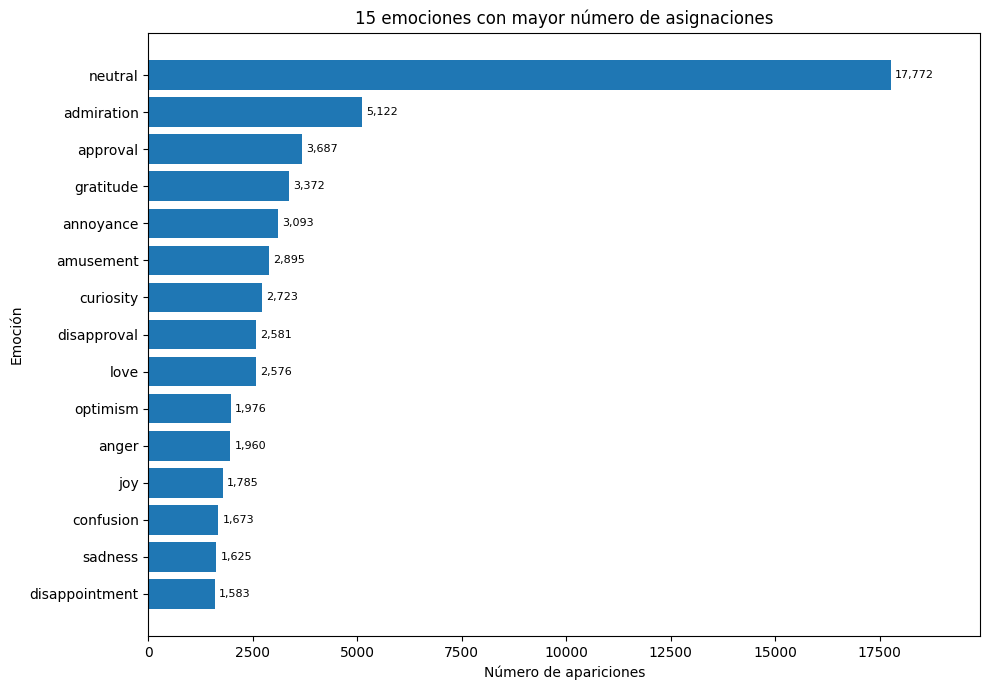

,emotion,occurrences
0,neutral,17772
1,admiration,5122
2,approval,3687
3,gratitude,3372
4,annoyance,3093
5,amusement,2895
6,curiosity,2723
7,disapproval,2581
8,love,2576
9,optimism,1976


In [12]:
top_emotions = emotion_counts.head(15).sort_values("occurrences", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top_emotions["emotion"], top_emotions["occurrences"])
ax.set_title("15 emociones con mayor número de asignaciones")
ax.set_xlabel("Número de apariciones")
ax.set_ylabel("Emoción")
ax.bar_label(bars, labels=[f"{value:,}" for value in top_emotions["occurrences"]], padding=3, fontsize=8)
ax.set_xlim(0, top_emotions["occurrences"].max() * 1.12)
fig.tight_layout()
plt.show()

display(emotion_counts.head(15))

**Qué observamos:** el gráfico ordena las emociones según sus apariciones en las etiquetas. Permite reconocer cuáles son más frecuentes y cuáles tienen menor presencia dentro de las 15 seleccionadas. Los conteos corresponden a asignaciones de etiquetas y no a comentarios únicos.

### 9.3 Distribución de la longitud de los comentarios

Se calcula la cantidad de palabras de cada comentario y se representa su distribución mediante un histograma. Esta inspección ayuda a conocer la extensión habitual de los textos antes de definir el procesamiento para los modelos.

,word_count
count,54263.000000
mean,12.828354
std,6.705293
min,1.000000
25%,7.000000
50%,12.000000
75%,18.000000
max,33.000000


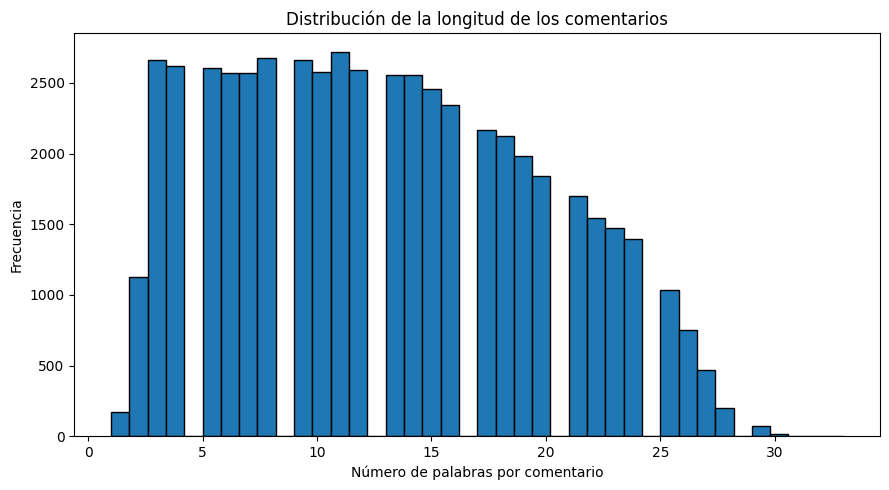

In [13]:
text_lengths = df["text"].fillna("").astype(str).str.split().str.len()
length_summary = text_lengths.describe(percentiles=[0.25, 0.50, 0.75]).to_frame(name="word_count")
display(length_summary)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(text_lengths, bins=40, edgecolor="black")
ax.set_title("Distribución de la longitud de los comentarios")
ax.set_xlabel("Número de palabras por comentario")
ax.set_ylabel("Frecuencia")
fig.tight_layout()
plt.show()

**Qué observamos:** el histograma muestra en qué rangos se concentra la longitud de los comentarios y permite detectar textos considerablemente más largos que el resto. La tabla descriptiva complementa la gráfica con medidas como la media, la mediana y los cuartiles. Esta información puede orientar decisiones posteriores sobre la longitud de secuencia, pero no determina por sí sola un límite de truncamiento.

### 9.4 Número de emociones asignadas por comentario

Se cuenta cuántas etiquetas de emoción tiene cada comentario y se representa la frecuencia de cada cantidad. Esta gráfica permite observar si predominan los comentarios con una sola emoción o si son comunes las etiquetas múltiples.

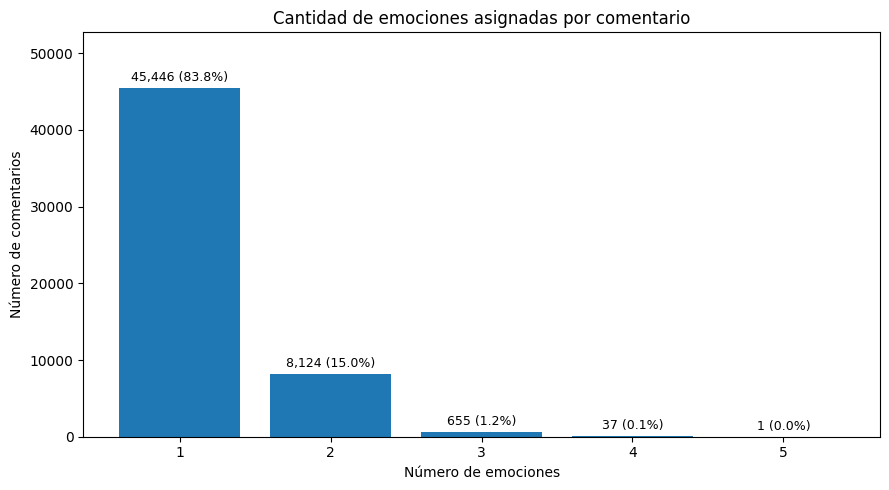

,comments,percentage
emotions,,
1,45446,83.75
2,8124,14.97
3,655,1.21
4,37,0.07
5,1,0.00


In [14]:
labels_per_comment = df["emotions"].map(len)
label_distribution = labels_per_comment.value_counts().sort_index()
label_percent = label_distribution / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(label_distribution.index.astype(str), label_distribution.values)
ax.set_title("Cantidad de emociones asignadas por comentario")
ax.set_xlabel("Número de emociones")
ax.set_ylabel("Número de comentarios")
ax.bar_label(
    bars,
    labels=[f"{value:,} ({percent:.1f}%)" for value, percent in zip(label_distribution.values, label_percent)],
    padding=3,
    fontsize=9,
)
ax.set_ylim(0, max(label_distribution.values) * 1.16)
fig.tight_layout()
plt.show()

display(pd.DataFrame({"comments": label_distribution, "percentage": label_percent.round(2)}))

**Qué observamos:** cada barra representa los comentarios que tienen una cantidad determinada de etiquetas emocionales. La distribución permite confirmar visualmente que el conjunto admite múltiples emociones por comentario, por lo que no debe interpretarse como una clasificación estrictamente de una sola etiqueta.

### 9.5 Resumen automático de las visualizaciones

La siguiente celda imprime algunos valores calculados a partir de los datos para apoyar la interpretación de las gráficas sin depender de estimaciones visuales.

In [15]:
largest_sentiment = sentiment_plot.idxmax()
smallest_sentiment = sentiment_plot.idxmin()
most_frequent_emotion = emotion_counts.iloc[0]["emotion"]
most_frequent_emotion_count = int(emotion_counts.iloc[0]["occurrences"])
median_words = float(text_lengths.median())
most_common_label_count = int(label_distribution.idxmax())

print(f"Grupo de sentimiento con más comentarios: {largest_sentiment} ({sentiment_plot.max():,}).")
print(f"Grupo de sentimiento con menos comentarios: {smallest_sentiment} ({sentiment_plot.min():,}).")
print(f"Emoción individual más frecuente: {most_frequent_emotion} ({most_frequent_emotion_count:,} apariciones).")
print(f"Mediana de palabras por comentario: {median_words:.1f}.")
print(f"Cantidad de emociones más común por comentario: {most_common_label_count}.")

Grupo de sentimiento con más comentarios: positive (19,020).
Grupo de sentimiento con menos comentarios: mixed (4,200).
Emoción individual más frecuente: neutral (17,772 apariciones).
Mediana de palabras por comentario: 12.0.
Cantidad de emociones más común por comentario: 1.


**Interpretación:** estos indicadores resumen las tendencias principales observadas. Deben leerse junto con las gráficas y las tablas anteriores. La longitud de texto y el número de etiquetas describen características del conjunto; cualquier decisión de preprocesamiento debe justificarse también con los requisitos del modelo y las pruebas posteriores.